# Human difficulty index for bandaged cubes

The first study measured how hard a bandaged cube is for an **optimal computer solver**: number of
positions, God's number, mean optimal solution, and the shortest algorithms. Solving by hand showed
that this misses the point. Puzzle B looked hard and was easy, and A looked like a 3x3x3 but stalled
on a 2-edge flip. This index instead estimates the work of a **commutator solve**, in moves:

1. **navigation**: bring the puzzle back to its home shape (mean moves from a random position).
2. **load**: fix every class of pieces (free corners, free edges, each family of congruent glued
   blocks) with tools: 3-cycles, 2-flips, 2-twists and block 3-cycles. The number of applications a
   random position needs, times the cost of one application.
3. **alignment**: configurations no tool reaches (on the 3x3x3, parity) are fixed with plain moves.
   A large unreachable part also gets a penalty, because the solver needs another method.
4. **discovery**: a tool is *known* if one of a dozen standard 3x3x3 algorithms (U-perms, A-perms,
   M-slice flips, corner twists) does the job on this puzzle in some grip of the cube. Otherwise the
   solver must discover one, and the cost is the length of X in the shortest commutator `[X, Y]`
   (Y one face turn) that does it, weighted ×5.

```
total = navigation + load + alignment + 5 × discovery + penalty
index = total / total(3x3x3)
```

An index of 1 means a commutator solve about as much work as a 3x3x3; 2 means twice the work.
Two parameters are guesses for now: the discovery weight (5) and the setup moves per tool
application (2). The sensitivity section shows how much they matter.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rubik

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 70)

NAMED = [("A", "F + FD | FL + FLD | L + LD"),
         ("B", "LDB + LD + LDF | RDB + RD + RDF"),
         ("Glued", "UBR+UR | UFL+UF | ULB+UB | UL+U | DRB+DR | DFR+FR | DLF+FL | DBL+BL | BR+R | DF+F | DL+L | DB+D+B")]
# 17 puzzles from the random study, evenly spread over state-space size (at least 1,000 positions)
RANDOM = ["B018", "B043", "B011", "B008", "B066", "B028", "B007", "B001", "B024", "B012",
          "B032", "B050", "B025", "B010", "B020", "B015", "B058"]

study = {x["id"]: x for x in json.load(open("../study/results.json", encoding="utf-8"))}
two = {x["name"]: x for x in json.load(open("../study/two_bandages.json", encoding="utf-8"))}
puzzles = [("3x3x3", "")] + NAMED + [(i, study[i]["spec"]) for i in RANDOM]

def run(**kw):
    return {name: rubik.human_difficulty(spec or None, **kw) for name, spec in puzzles}

H = run()
json.dump([{"name": n, **d} for n, d in H.items()], open("../study/human_index.json", "w"), indent=1)
base = H["3x3x3"]["total"]

## Ranking

Old KPIs for comparison: the optimal-solver view (positions, mean optimal solution, God's number).
`≥` marks lower bounds. The glued puzzle's values come from a fresh `rubik.difficulty` run.

In [2]:
glued_old = rubik.difficulty(NAMED[2][1])
def old(name):
    if name == "3x3x3":
        return 19.64, "17.7", "20"
    if name in two:
        p = two[name]
    elif name == "Glued":
        p = glued_old
    else:
        p = study[name]
    mean = ("" if p["mean_distance_exact"] else "≥") + f"{p['mean_distance']:.1f}"
    god = str(p["gods_number"]) if p.get("gods_number") is not None else f"≥{p['gods_lower']}"
    return np.log10(p["states"]), mean, god

rows = []
for name, d in H.items():
    ls, mean, god = old(name)
    rows.append({"puzzle": name, "index": d["total"] / base, "total moves": d["total"],
                 "navigation": d["navigation"], "load": d["load"], "alignment": d["align"],
                 "discovery ×5": 5 * d["discovery"], "penalty": d["penalty"], "transfer": d["transfer"],
                 "shapes": d["shapes"], "log10 states": ls, "mean optimal": mean, "God's number": god,
                 "bandage": d["bandage"]})
T = pd.DataFrame(rows).set_index("puzzle").sort_values("index")
T.style.format({"index": "{:.2f}", "total moves": "{:.0f}", "navigation": "{:.1f}", "load": "{:.0f}",
                "alignment": "{:.1f}", "discovery ×5": "{:.0f}", "penalty": "{:.0f}", "transfer": "{:.0%}",
                "log10 states": "{:.1f}"}).background_gradient(subset=["index"], cmap="RdYlGn_r")

,index,total moves,navigation,load,alignment,discovery ×5,penalty,transfer,shapes,log10 states,mean optimal,God's number,bandage
puzzle,,,,,,,,,,,,,
Glued,0.38,61,5.2,31,0.0,25,0,0%,440,6.0,18.8,28,UBR+UR | UFL+UF | ULB+UB | DRB+DR | DFR+FR | DLF+FL | DBL+BL | UL+U | BR+R | DF+F | DL+L | DB+D+B
B,0.44,71,2.0,66,2.4,0,0,31%,42,12.3,≥20.4,≥21,DFR+DRB+DR | DLF+DBL+DL
B018,0.76,122,6.6,43,2.5,70,0,0%,94,4.4,76.2,155,UBR+UB | DBL+DB | FR+F | DLF+DR+DF+DL+D | UR+BR+R+B
B010,0.86,139,2.6,136,0.5,0,0,100%,88,17.5,≥13.0,≥13,UBR+UR | BL+L
B025,0.87,142,1.2,140,0.6,0,0,77%,8,16.8,≥15.0,≥15,UR+DR+R | FL+L
B020,0.90,146,1.8,144,0.5,0,0,100%,24,18.3,≥12.0,≥12,URF+UF
B015,0.96,155,0.8,154,0.5,0,0,100%,4,18.9,≥12.0,≥12,DL+D
B058,0.96,155,0.8,154,0.5,0,0,100%,4,18.9,≥12.0,≥12,DL+L
B032,0.99,160,4.3,110,0.9,45,0,31%,800,16.1,≥14.9,≥15,DFR+DR | DRB+BR | BL+L


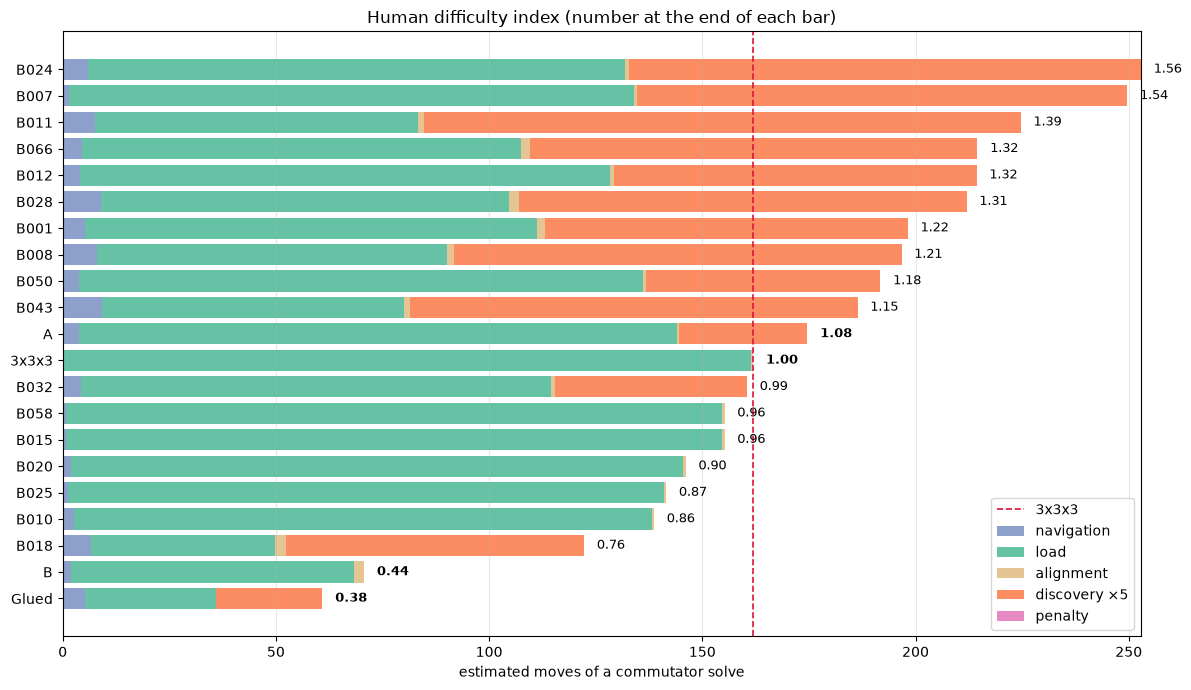

In [3]:
parts = ["navigation", "load", "alignment", "discovery ×5", "penalty"]
colors = ["#8da0cb", "#66c2a5", "#e5c494", "#fc8d62", "#e78ac3"]
fig, ax = plt.subplots(figsize=(12, 7))
left = np.zeros(len(T))
for p, c in zip(parts, colors):
    ax.barh(T.index, T[p], left=left, color=c, label=p)
    left += T[p].values
ax.axvline(base, c="crimson", ls="--", lw=1.2, label="3x3x3")
for i, (name, r) in enumerate(T.iterrows()):
    ax.text(r["total moves"] + 3, i, f"{r['index']:.2f}", va="center", fontsize=9,
            fontweight="bold" if name in ("A", "B", "Glued", "3x3x3") else "normal")
ax.set_xlabel("estimated moves of a commutator solve"); ax.legend(loc="lower right"); ax.grid(axis="x", alpha=.3)
ax.set_title("Human difficulty index (number at the end of each bar)")
plt.tight_layout()

## The named puzzles, tool by tool

For each class of pieces: how many there are, how many configurations the puzzle allows (G) and how
many the tools can reach (K), how many tool applications a random position needs, and for each tool
the standard algorithm that transfers, or else the shortest commutator found.

In [4]:
def tools_table(name):
    out = []
    for c in H[name]["classes"]:
        base_row = {"class": c["name"], "pieces": c["units"], "G": f"{c['configs']:.3g}", "K": f"{c['tool_configs']:.3g}",
                    "perm apps": round(c["perm_tools"], 2), "orient apps": round(c["orient_tools"], 2)}
        if not c["tools"]:
            out.append({**base_row, "tool": "(none needed)" if c["configs"] <= 24 else "(none)"})
        for t in c["tools"]:
            out.append({**base_row, "tool": t["kind"], "possible": t["possible"],
                        "known 3x3x3 alg": t["known"] or "—",
                        "commutator": t["commutator"] or f"none with |X| ≤ 6",
                        "cost": t["cost"]})
    return pd.DataFrame(out).astype(object).fillna("")

for name in ["3x3x3", "A", "B", "Glued"]:
    d = H[name]
    print(f"{name}: index {d['total'] / base:.2f}, transfer {d['transfer']:.0%}, shapes {d['shapes']}, "
          f"discovery {d['discovery']:.0f}")
    display(tools_table(name))

3x3x3: index 1.00, transfer 100%, shapes 1, discovery 0


,class,pieces,G,K,perm apps,orient apps,tool,possible,known 3x3x3 alg,commutator,cost
0,free corners,8,8.82e+07,4.41e+07,2.6,2.67,3-cycle,1008,R U R' D R U' R' D',"[D' R' D, L]",10.0
1,free corners,8,8.82e+07,4.41e+07,2.6,2.67,2-twist,56,R' D' R D R' D' R D U D' R' D R D' R' D R U',"[L F' U2 F L', D2]",20.0
2,free edges,12,9.81e+11,4.9e+11,4.44,3.0,3-cycle,1760,M2 U M U2 M' U M2,"[L2 D2 L2, F2]",9.0
3,free edges,12,9.81e+11,4.9e+11,4.44,3.0,2-flip,66,M' U M' U M' U2 M U M U M U2,"[L2 D F B' L U2, B2]",14.0


A: index 1.08, transfer 69%, shapes 300, discovery 6


,class,pieces,G,K,perm apps,orient apps,tool,possible,known 3x3x3 alg,commutator,cost
0,free corners,7,3.67e+06,1.84e+06,2.23,2.35,3-cycle,630,[x: R U R' D R U' R' D'],"[U R U', L]",10.0
1,free corners,7,3.67e+06,1.84e+06,2.23,2.35,2-twist,42,[x: R' D' R D R' D' R D U D' R' D R D' R' D R U'],"[U R2 U' B' R2 B, L']",20.0
2,free edges,9,9.29e+07,4.64e+07,3.11,2.3,3-cycle,672,R U R' U' M' U R U' r',"[R2 B2 R2, U2]",11.0
3,free edges,9,9.29e+07,4.64e+07,3.11,2.3,2-flip,36,—,"[R2 U' F' B L' U2, B2]",16.0


B: index 0.44, transfer 31%, shapes 42, discovery 0


,class,pieces,G,K,perm apps,orient apps,tool,possible,known 3x3x3 alg,commutator,cost
0,free corners,4,24,1,0.0,0.0,(none needed),,,,
1,free edges,10,1.86e+09,9.29e+08,3.5,2.48,3-cycle,960.0,M2 U M U2 M' U M2,"[U' D F2 U D', R2]",9.0
2,free edges,10,1.86e+09,9.29e+08,3.5,2.48,2-flip,45.0,M' U M' U M' U2 M U M U M U2,none with |X| ≤ 6,14.0
3,blocks like DFR+DRB+DR,2,4,1,0.0,0.0,(none needed),,,,


Glued: index 0.38, transfer 0%, shapes 440, discovery 5


,class,pieces,G,K,perm apps,orient apps,tool,possible,known 3x3x3 alg,commutator,cost
0,free corners,1,1,1,0.0,0.0,(none needed),,,,
1,blocks like UBR+UR,7,2.52e+03,2.52e+03,2.19,0.0,block 3-cycle,70.0,—,"[F R U F' L', U]",14.0


**Reading it.**

* **A** keeps most of the 3x3x3 toolkit: an edge 3-cycle works as is, and the corner 3-cycle and
  twist work with the cube held in another grip (`x`). The 2-flip does not: every standard flip is
  blocked by the glued pieces in the down-front-left, so the solver must discover one (a commutator
  with a 6-move X). That is exactly where you got stuck, and it alone puts A above the 3x3x3.
* **B** has nothing to do on its corners (G = 24, K = 1: they fall into place). Its edges are served
  by standard algorithms held in the right grip, including an M-slice flip. That makes it the
  easiest of the named three.
* **The glued puzzle** has no standard tool at all, but only 7 blocks to place. Its block 3-cycle
  is a 12-move commutator `[F R U F' L', U]` (a 5-move X). Its weak spot in this model is the shape:
  440 shapes and only about 4 legal turns per position make setups more expensive than the
  fixed 2 moves assumed here, so the index probably flatters it.

## Index against the old KPIs

If the index were just the state-space size or the optimal solution length in disguise, it would
not need computing. It mostly isn't.

,Spearman correlation with the index
log10 states,-0.17
mean optimal,0.27
transfer,-0.50
shapes,0.45


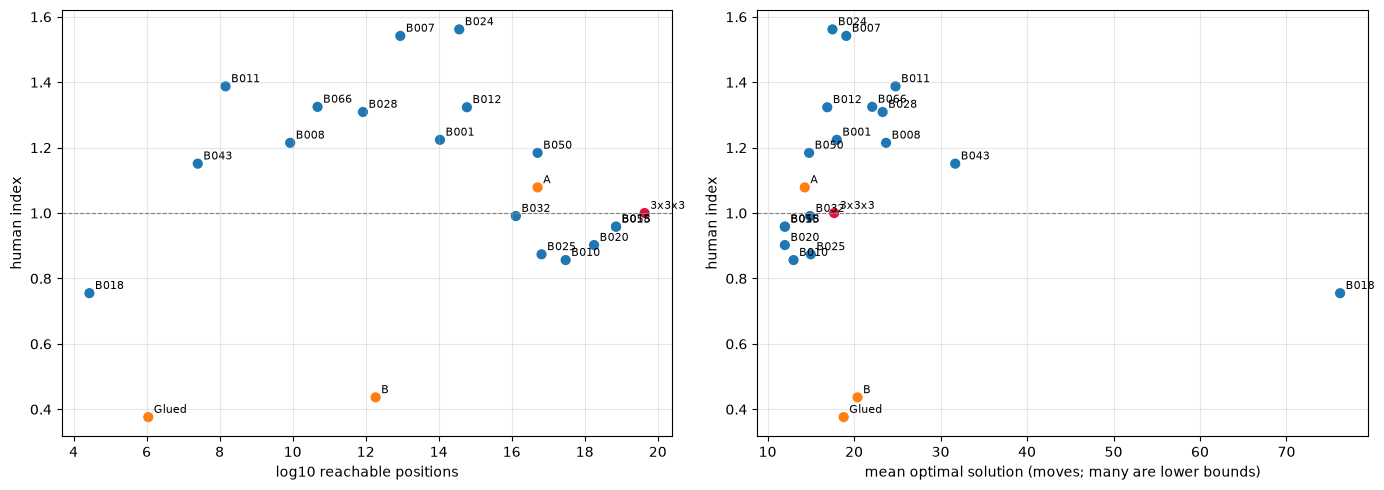

In [5]:
def num(s):
    return float(str(s).lstrip("≥"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, lab in [(axes[0], "log10 states", "log10 reachable positions"), (axes[1], "mean optimal", "mean optimal solution (moves; many are lower bounds)")]:
    x = T[col].map(num) if col == "mean optimal" else T[col]
    ax.scatter(x, T["index"], s=40, c=["crimson" if n == "3x3x3" else "C1" if n in ("A", "B", "Glued") else "C0" for n in T.index])
    for n, xi, yi in zip(T.index, x, T["index"]):
        ax.annotate(n, (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=8)
    ax.axhline(1, c="grey", ls="--", lw=.8); ax.set_xlabel(lab); ax.set_ylabel("human index"); ax.grid(alpha=.3)
plt.tight_layout()
rank = T.assign(ms=T["mean optimal"].map(num))[["index", "log10 states", "ms", "transfer", "shapes"]].rank()
pd.Series({c: rank["index"].corr(rank[c]) for c in ["log10 states", "ms", "transfer", "shapes"]},
          name="Spearman correlation with the index").rename({"ms": "mean optimal"}).to_frame().round(2)

The strongest link is **transfer**: puzzles where no standard algorithm survives are the hard ones.
That fits your experience, and it is something none of the old KPIs could see.

## Sensitivity to the two guessed parameters

Does the ranking survive other choices of the discovery weight and the setup cost?

In [6]:
variants = {"w=0": dict(discovery_weight=0.0), "w=2.5": dict(discovery_weight=2.5), "w=5 (default)": {},
            "w=10": dict(discovery_weight=10.0), "setup=1": dict(setup=1.0), "setup=4": dict(setup=4.0)}
S = {}
for label, kw in variants.items():
    R = H if not kw else run(**kw)
    b = R["3x3x3"]["total"]
    S[label] = {n: d["total"] / b for n, d in R.items()}
S = pd.DataFrame(S).loc[T.index]
display(S.style.format("{:.2f}").background_gradient(cmap="RdYlGn_r", axis=None))
print("rank correlation with the default ranking:")
print(S.rank().corr(method="pearson")["w=5 (default)"].round(2).to_string())

,w=0,w=2.5,w=5 (default),w=10,setup=1,setup=4
Glued,0.22,0.30,0.38,0.53,0.39,0.35
B,0.44,0.44,0.44,0.44,0.43,0.44
B018,0.32,0.54,0.76,1.19,0.80,0.68
B010,0.86,0.86,0.86,0.86,0.86,0.85
B025,0.87,0.87,0.87,0.87,0.88,0.87
B020,0.90,0.90,0.90,0.90,0.90,0.90
B015,0.96,0.96,0.96,0.96,0.96,0.96
B058,0.96,0.96,0.96,0.96,0.96,0.96
B032,0.71,0.85,0.99,1.27,1.01,0.95
3x3x3,1.00,1.00,1.00,1.00,1.00,1.00


rank correlation with the default ranking:
w=0             -0.00
w=2.5            0.78
w=5 (default)    1.00
w=10             0.95
setup=1          0.99
setup=4          0.99


**Reading it.** The setup cost hardly matters (rank correlation 0.99). The discovery term is what
orders the puzzles: without it (w = 0) the ranking is unrelated to the default one, while any weight
from 2.5 to 10 keeps it (0.78 to 0.95). The index is mostly a statement about which tools a solver
has to find. A stays above B in every variant.

## Caveats and next step

* Two parameters are guesses: the discovery weight and the setup cost. The ranking holds for
  discovery weights from 2.5 to 10, but the absolute index values are not calibrated.
* Setups are a flat 2 moves. On heavily bandaged puzzles (few legal turns, many shapes) real setups
  cost more, so those puzzles are probably underrated (the glued puzzle in particular).
* The standard library is a dozen common algorithms. A solver who knows more transfers more.
* Commutators are searched as `[X, Y]` with Y one face turn and |X| ≤ 6. Conjugated or longer
  commutators count as "not found" at depth 7.
* **Calibration** is what would make this trustworthy. Rate (or time) your solves of a handful of
  these puzzles, then fit the discovery weight and setup cost so the index orders them the same way.